# Aula 8 - Testes Paramétricos

**Aluno:** Esdras Felipe Chaves Pinto Nascimento e Silva  
**Matrícula:** `20230051975`  
**Disciplina:** Ciência de Dados  
**Material Oficial:** [Aula 8 - Testes Paramétricos](https://oandrefonseca.github.io/data-science/aulas/08-testes-parametricos.html)

---


# Aula 8 - Testes Paramétricos

## Motivação

Na Aula 7, construímos a distribuição nula de duas formas: embaralhando
rótulos, no teste de permutação, e por fórmula, no teste *t* de Welch.
Vimos também como ler o *p*-valor, como decidir com $\alpha$ e quais
erros essa decisão pode cometer. Nesta aula, partimos desse ponto e
respondemos a duas perguntas novas. **Quando** a distribuição nula pode
vir de uma fórmula? E, diante de dados de natureza diferente, **qual**
fórmula usar?

Um teste paramétrico troca a simulação por uma curva teórica: *t*, *F*,
*Z* ou $\chi^2$. Essa troca só é segura quando os dados cumprem certas
premissas. A escolha da curva, por sua vez, depende do que medimos e de
como as observações foram coletadas. A primeira parte do roteiro trata
dessas condições. A segunda aplica sete testes a sete problemas reais,
cada um com seu próprio conjunto de dados.

> **Qual teste responde à minha pergunta, e posso confiar nele?**

## Objetivos de aprendizagem

Ao final deste roteiro, você será capaz de:

1.  Explicar o que torna um teste *paramétrico* e o que se ganha e se
    arrisca com ele.
2.  Verificar normalidade, homocedasticidade e independência com Q-Q
    plot, Shapiro-Wilk e o desenho do estudo.
3.  Escolher o teste pelo objetivo, pela escala da variável e pelo
    delineamento.
4.  Aplicar em Python os testes *t* de uma amostra, de Welch e pareado,
    a ANOVA, a correlação de Pearson, o teste *Z* de duas proporções e o
    $\chi^2$ de independência.
5.  Interpretar os resultados e reconhecer quando migrar para um teste
    não paramétrico.

> **Como usar este roteiro**
>
> O roteiro usa cinco conjuntos de dados, cada um salvo em
> `<nome>/data/`:
>
> | Base       | Origem                                            | Casos      |
> |------------|---------------------------------------------------|------------|
> | `mtcars`   | Revista *Motor Trend*, 1974 (já usada na Aula 7)  | 1 e 5      |
> | `penguins` | Pinguins do arquipélago Palmer, Antártida         | 2          |
> | `sleep`    | Ensaio clínico com dois soníferos (Student, 1908) | 3          |
> | `iris`     | Flores de três espécies de íris (Fisher, 1936)    | 4          |
> | `titanic`  | Passageiros do naufrágio do Titanic, 1912         | 2.3, 6 e 7 |
>
> Além das bibliotecas da Aula 7, usamos o `statsmodels` no caso 6.

# 1. Preparando os dados

Começamos com as bibliotecas e as cinco bases. A seção 1.1 apresenta as
bases que aparecem pela primeira vez no curso.

In [1]:
import os
# Importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Carrega as cinco bases
mtcars = pd.read_csv("../../datasets/mtcars.csv" if os.path.exists("../../datasets/mtcars.csv") else "datasets/mtcars.csv")
penguins = pd.read_csv("../../datasets/penguins.csv" if os.path.exists("../../datasets/penguins.csv") else "datasets/penguins.csv")
sleep = pd.read_csv("../../datasets/sleep.csv" if os.path.exists("../../datasets/sleep.csv") else "datasets/sleep.csv")
iris = pd.read_csv("../../datasets/iris.csv" if os.path.exists("../../datasets/iris.csv") else "datasets/iris.csv")
titanic = pd.read_csv("../../datasets/titanic.csv" if os.path.exists("../../datasets/titanic.csv") else "datasets/titanic.csv")

## 1.1 Conhecendo as bases

O `mtcars` já foi apresentado na Aula 7: são 32 linhas, uma por modelo
de carro, e 12 colunas. As outras quatro bases aparecem pela primeira
vez. Para cada uma, olhamos as cinco primeiras linhas e descrevemos suas
variáveis.

As bases têm tamanhos bem diferentes, do ensaio clínico com 20 registros
ao Titanic com quase 900 passageiros. Isso influencia diretamente as
decisões desta aula. Com 20 registros, a normalidade precisa ser
**verificada com cuidado**. Com centenas, o teorema central do limite
torna o teste *t* robusto, mas o Shapiro-Wilk passa a rejeitar desvios
pequenos.

### `penguins`

Medidas de pinguins adultos coletadas entre 2007 e 2009 em três ilhas do
arquipélago Palmer, na Antártida. São 344 linhas, uma por pinguim, e 8
colunas.

In [3]:
# Cinco primeiras linhas da base de pinguins
penguins.head()

,species,island,bill_len,bill_dep,flipper_len,body_mass,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


-   `species`: espécie do pinguim (Adelie, Chinstrap ou Gentoo).
-   `island`: ilha onde o animal foi observado (Biscoe, Dream ou
    Torgersen).
-   `bill_len`: comprimento do bico, em milímetros.
-   `bill_dep`: profundidade (altura) do bico, em milímetros.
-   `flipper_len`: comprimento da nadadeira, em milímetros.
-   `body_mass`: massa corporal, em gramas.
-   `sex`: sexo do animal (`female` ou `male`). Está ausente em 11
    pinguins.
-   `year`: ano da observação (2007, 2008 ou 2009).

### `sleep`

Dados do ensaio clínico usado por Student em 1908 para apresentar o
teste *t*. Dez pacientes receberam dois soníferos, em períodos
diferentes. São 20 linhas, uma por paciente e droga, e 3 colunas.

In [4]:
# Cinco primeiras linhas da base do ensaio de sono
sleep.head()

,extra,group,ID
0,0.7,1,1
1,-1.6,1,2
2,-0.2,1,3
3,-1.2,1,4
4,-0.1,1,5


-   `extra`: aumento nas horas de sono em relação ao período sem
    medicamento. Valores negativos indicam que o paciente dormiu menos.
-   `group`: droga administrada (1 ou 2).
-   `ID`: identificação do paciente (1 a 10). Cada paciente aparece duas
    vezes, uma com cada droga.

### `iris`

Medidas de flores de três espécies do gênero *Iris*, publicadas por R.
A. Fisher em 1936. São 150 linhas, uma por flor (50 de cada espécie), e
5 colunas.

In [5]:
# Cinco primeiras linhas da base de íris
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


-   `sepal_length` e `sepal_width`: comprimento e largura da sépala, a
    parte externa e geralmente verde que protege a flor, em centímetros.
-   `petal_length` e `petal_width`: comprimento e largura da pétala, em
    centímetros.
-   `species`: espécie da flor (setosa, versicolor ou virginica).

### `titanic`

Registros de passageiros do naufrágio do Titanic, em abril de 1912. São
891 linhas, uma por passageiro, e 15 colunas.

In [6]:
# Cinco primeiras linhas da base do Titanic
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


-   `survived`: se o passageiro sobreviveu (1) ou não (0).
-   `pclass`: classe da passagem (1, 2 ou 3).
-   `sex`: sexo do passageiro (`female` ou `male`).
-   `age`: idade, em anos. Está ausente em 177 passageiros.
-   `sibsp`: número de irmãos e cônjuges a bordo.
-   `parch`: número de pais e filhos a bordo.
-   `fare`: valor pago pela passagem, em libras esterlinas.
-   `embarked`: porto de embarque, abreviado (C, Q ou S).
-   `class`: classe da passagem, por extenso (First, Second ou Third).
-   `who`: categoria do passageiro (`man`, `woman` ou `child`).
-   `adult_male`: se o passageiro é um homem adulto (`True` ou `False`).
-   `deck`: convés da cabine. Está ausente em 688 passageiros.
-   `embark_town`: porto de embarque, por extenso (Cherbourg, Queenstown
    ou Southampton).
-   `alive`: sobrevivência em texto (`yes` ou `no`), equivalente a
    `survived`.
-   `alone`: se o passageiro viajava sem familiares (`True` ou `False`).

Algumas colunas do Titanic repetem a mesma informação em formatos
diferentes: `class` e `pclass`, `alive` e `survived`, `embark_town` e
`embarked`. Nos casos 6 e 7, usamos as versões numéricas ou abreviadas.

# 2. O que um teste paramétrico exige

## 2.1 A curva teórica e sua largura

Um teste paramétrico não simula a distribuição nula: ele supõe que os
dados seguem uma família conhecida, como a normal, e lê o *p*-valor como
uma área sob uma curva teórica. No caso de uma média, a estatística e a
largura da curva são:

$$
t = \frac{\bar{x} - \mu_0}{SE}
\qquad\qquad
SE = \frac{s}{\sqrt{n}}
$$

Aqui, $\mu_0$ é o valor de referência sob $H_0$. Sob $H_0$, *t* segue a
distribuição *t* de Student com $n - 1$ graus de liberdade.

O erro-padrão decide se uma diferença é grande ou pequena. Considere a
mesma diferença de 1,5 unidade em duas amostras de 20 observações, uma
com dados pouco dispersos ($SE = 0{,}52$) e outra com dados muito
dispersos ($SE = 1{,}29$). Na
<a href="#fig-same-diff" class="quarto-xref">Figura 1</a>, a diferença
está na mesma posição nos dois painéis. O que muda é a largura da curva
ao redor dela.

Dividindo a diferença pelo erro-padrão, os dois cenários vão para a
mesma régua (<a href="#fig-t-scale" class="quarto-xref">Figura 2</a>). O
primeiro dá $t = 2{,}88$ e cai na região de rejeição
($p \approx 0{,}01$). O segundo dá $t = 1{,}16$ e cai no miolo da curva
($p \approx 0{,}26$).

A diferença é a mesma, mas as conclusões são opostas. E nenhuma das duas
merece confiança se as premissas do teste não valerem.

## 2.2 As três premissas clássicas

Premissas violadas distorcem o erro-padrão e a forma da distribuição
nula. Na prática, o $\alpha$ de 5% deixa de ser 5%.

| Premissa | O que afirma | Se falhar |
|------------------------|------------------------|------------------------|
| **Normalidade** | A resposta, ou os resíduos do modelo, segue uma distribuição normal na população | A distribuição da estatística muda, e o *p*-valor se descalibra em amostras pequenas |
| **Homocedasticidade** | A variância é a mesma em todos os grupos: $\sigma_1^2 = \sigma_2^2 = \dots$ | O erro-padrão combinado fica errado. A solução é a versão de Welch |
| **Independência** | A medida de uma unidade não influencia as demais | Nenhum ajuste de fórmula resolve. É preciso mudar o desenho do teste, por exemplo para o pareado |

A independência é a premissa mais crítica e também a única que não se
verifica olhando os dados: ela depende de **como** foram coletados. A
homocedasticidade se verifica comparando os desvios-padrão dos grupos ou
com o teste de Levene, que aparecerá nos casos 2 e 4. A normalidade tem
ferramentas próprias, apresentadas a seguir.

## 2.3 Verificando a normalidade

Há dois instrumentos complementares:

-   **Diagnóstico gráfico.** O histograma com a curva normal revela
    assimetria, bimodalidade e valores atípicos. O **Q-Q plot** compara
    os quantis da amostra com os quantis esperados de uma normal. Se os
    dados forem normais, os pontos seguem uma reta.
-   **Teste formal.** O **Shapiro-Wilk** testa $H_0$: os dados vêm de
    uma normal. A estatística $W$ varia de 0 a 1, e valores próximos de
    1 indicam forma próxima da normal. Se $p < \alpha$, rejeitamos a
    normalidade.

O gráfico mostra **como** os dados fogem da normal. O teste diz **se** o
desvio é maior que o esperado pelo acaso. Cada forma de distribuição
deixa uma assinatura típica no Q-Q plot:

| Forma da distribuição | Assinatura no Q-Q plot |
|------------------------------------|------------------------------------|
| Normal | Pontos sobre a reta |
| Assimetria à direita | Curva em U: as duas pontas acima da reta |
| Assimetria à esquerda | Arco (∩): as duas pontas abaixo da reta |
| Caudas pesadas | Forma de S: as pontas fogem da reta em sentidos opostos |
| Caudas leves | S invertido: as pontas achatadas |
| Bimodal | Degrau no meio: faltam observações no centro |

Vejamos dois casos reais: o consumo dos carros do `mtcars` e o preço das
passagens do Titanic.

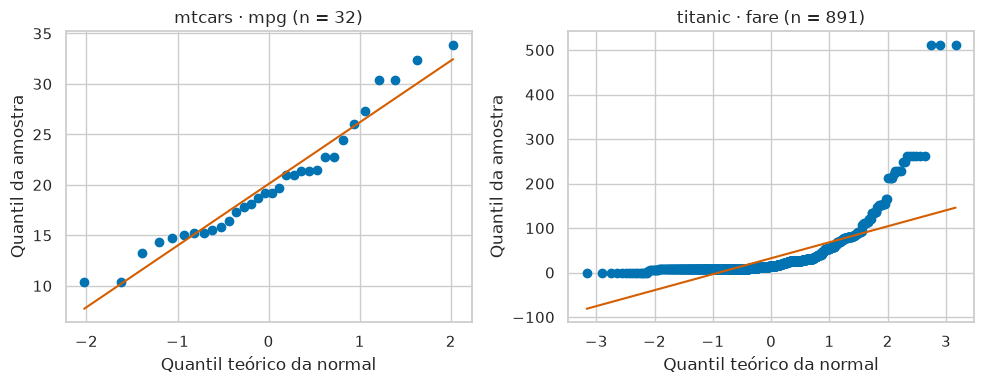

,W,p
mpg,0.947565,1.228814e-01
fare,0.521891,1.084044e-43


In [7]:
# Q-Q plot e Shapiro-Wilk em duas variáveis reais
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, values, title in zip(
    axes,
    [mtcars["mpg"], titanic["fare"]],
    ["mtcars · mpg (n = 32)", "titanic · fare (n = 891)"],
):
    stats.probplot(values, dist="norm", plot=ax)
    ax.set(title=title, xlabel="Quantil teórico da normal",
           ylabel="Quantil da amostra")

plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        "mpg": stats.shapiro(mtcars["mpg"]),
        "fare": stats.shapiro(titanic["fare"]),
    },
    index=["W", "p"],
).T

Os dois diagnósticos concordam. No `mtcars`, os pontos seguem a reta,
com um leve afastamento só na cauda direita. O Shapiro-Wilk dá
$W \approx 0{,}95$ e $p \approx 0{,}12$: não rejeitamos a normalidade.
No Titanic, o Q-Q plot forma uma curva acentuada, a assinatura de forte
assimetria à direita. Algumas tarifas ficam quase 10 desvios-padrão
acima da média. O teste dá $W \approx 0{,}52$ e um *p*-valor
praticamente zero.

> **Cuidado com o tamanho da amostra**
>
> Com *n* pequeno, o Shapiro-Wilk tem pouco poder e deixa passar desvios
> importantes. Com *n* grande, rejeita desvios irrelevantes. Por isso, a
> decisão nunca deve se apoiar só no *p*-valor do teste: olhe sempre o
> Q-Q plot. Lembre também que, pelo teorema central do limite, com
> amostras moderadas ou grandes o que precisa ser aproximadamente normal
> é a **média**, não cada observação.

## 2.4 O tipo de variável

Saber a forma da distribuição não basta. O teste também depende de **o
que** medimos. A escala da variável resposta define quais operações
fazem sentido e, portanto, quais testes podem ser aplicados:

| Tipo | Exemplo | Operações permitidas |
|------------------------|------------------------|------------------------|
| Numérica contínua | Consumo em mpg (`mtcars`) | Média, desvio-padrão, todas as operações |
| Numérica discreta | Número de carburadores (`mtcars`): 1, 2, 3, 4, 6 ou 8 | Contagem, ordem, mediana, moda. Média com cautela |
| Categórica binária | Sobreviveu ou não (`titanic`) | Frequência e proporção |
| Categórica ordinal | Escala Likert de 1 a 5, escolaridade | Ordenação, mediana, percentis |
| Categórica nominal | Espécie (`iris`, `penguins`), classe da cabine (`titanic`) | Contagem, moda, tabela de contingência |

Em uma variável ordinal, há ordem entre os níveis, mas a distância entre
eles não é medida diretamente. Tratar uma escala Likert como contínua,
sem justificativa, invalida o cálculo do erro-padrão.

## 2.5 Amostras independentes ou pareadas

O teste depende ainda de **como** as observações foram coletadas:

|  | Independentes | Pareadas (dependentes) |
|------------------------|------------------------|------------------------|
| Exemplo | Massa de pinguins machos e fêmeas (`penguins`) | Sono dos mesmos pacientes com duas drogas (`sleep`) |
| Foco | Diferença entre médias: $\bar{x}_1 - \bar{x}_2$ | Média das diferenças individuais: $D = X_2 - X_1$ |
| Erro-padrão | Carrega a variação entre indivíduos | O pareamento cancela a variação de base de cada indivíduo |
| Poder | Menor, para o mesmo *n* | Maior: isola o efeito do tratamento |

A pergunta-chave é: **saber o valor de uma observação diz algo sobre uma
observação do outro grupo?** Se sim, as amostras são pareadas. O caso 3
mostra o que acontece quando essa estrutura é ignorada.

## 2.6 Três perguntas escolhem o teste

A escolha do teste resulta de três perguntas, feitas nesta ordem:

1.  **Qual o objetivo?** Comparar médias, comparar proporções ou medir
    associação.
2.  **Qual a escala?** Da resposta e da variável explicativa: contínua,
    binária ou nominal.
3.  **Qual o desenho?** Uma amostra, dois grupos ou três ou mais;
    independentes ou pareados.

Respondidas as três, o teste fica determinado, e resta verificar suas
premissas. A matriz abaixo resume os sete casos desta aula:

| Objetivo | Resposta | Explicativa e desenho | Teste | Caso |
|---------------|---------------|---------------|---------------|---------------|
| Média contra uma meta | Contínua | Nenhuma (valor $\mu_0$) | *t* de uma amostra | 1 · `mtcars` |
| Médias de 2 grupos | Contínua | Binária, independentes | *t* de Welch | 2 · `penguins` |
| Antes e depois | Contínua | 2 momentos, pareados | *t* pareado | 3 · `sleep` |
| Médias de 3 ou mais grupos | Contínua | Nominal, independentes | ANOVA + Tukey | 4 · `iris` |
| Associação linear | Contínua | Contínua | Pearson | 5 · `mtcars` |
| Proporções de 2 grupos | Binária | Binária, independentes | *Z* de duas proporções | 6 · `titanic` |
| Associação entre categorias | Nominal | Nominal, independentes | Qui-quadrado | 7 · `titanic` |

Errar a escolha, por exemplo usando um teste para amostras independentes
em dados pareados, ou vários testes *t* no lugar da ANOVA, altera as
taxas de erro dos tipos I e II.

# 3. Conceitos importantes

Esta seção reúne os conceitos que atravessam os sete casos. Os três
primeiros já foram vistos na Aula 7 e aparecem aqui apenas como
lembrete. Os demais são novos e ajudam a ler as saídas dos testes.

## 3.1 Hipóteses e *p*-valor

Todo teste confronta a hipótese nula $H_0$, de que não há efeito, com a
hipótese alternativa $H_1$, de que há. O *p*-valor é a probabilidade,
**supondo $H_0$ verdadeira**, de obter um resultado tão ou mais extremo
que o observado. Ele não é a probabilidade de $H_0$ ser verdadeira.
Neste roteiro, todos os testes são **bilaterais**: admitem diferenças
nos dois sentidos.

## 3.2 Nível de significância e erros de decisão

O nível de significância $\alpha$, em geral 0,05, é fixado antes da
análise: se $p \leq \alpha$, rejeitamos $H_0$. Rejeitar uma $H_0$
verdadeira é um erro do tipo I, cuja taxa é o próprio $\alpha$. Não
rejeitar uma $H_0$ falsa é um erro do tipo II. A probabilidade de
detectar um efeito que existe é o **poder** do teste, que cresce com o
tamanho da amostra.

## 3.3 Tamanho do efeito

Um *p*-valor pequeno indica que a diferença dificilmente é acaso, mas
não diz se ela é grande. Por isso, além do *p*-valor, reportamos o
**tamanho do efeito**. Nesta aula, ele aparece de várias formas: a
diferença de médias em gramas ou mpg, o coeficiente $r$ de Pearson, a
fração da variação explicada pela espécie na ANOVA ($\eta^2$) e o V de
Cramér no qui-quadrado.

## 3.4 Estatística de teste

Cada teste resume os dados em um único número, a **estatística de
teste**. Em quase todos os casos, ela tem a forma de uma razão entre
**sinal** e **ruído**: o efeito observado dividido pela variação que o
acaso produziria. Quanto maior a razão, mais o efeito se destaca do
acaso. Cada estatística tem a sua distribuição de referência sob $H_0$:

| Teste | Estatística | Sinal ÷ ruído | Distribuição sob $H_0$ |
|------------------|------------------|------------------|------------------|
| Testes *t* | $t$ | Diferença de médias ÷ erro-padrão | *t* de Student |
| ANOVA | $F$ | Variação entre grupos ÷ variação dentro dos grupos | *F* |
| Pearson | $r$ | Covariação ÷ variação de cada variável | *t* de Student, após conversão |
| *Z* de proporções | $Z$ | Diferença de proporções ÷ erro-padrão | Normal padrão |
| Qui-quadrado | $\chi^2$ | Soma das discrepâncias $(O - E)^2 / E$ | Qui-quadrado |

## 3.5 Graus de liberdade

As distribuições *t*, *F* e $\chi^2$ não são curvas únicas: cada uma é
uma família, e o membro certo é escolhido pelos **graus de liberdade**
(gl). Intuitivamente, eles contam quantas informações independentes
restam para estimar a variabilidade.

Pense em três números cuja média precisa ser 10. Você pode escolher os
dois primeiros à vontade, por exemplo 8 e 15, mas o terceiro já está
decidido: tem de ser 7. São três números, e só dois são livres. Da mesma
forma, cada parâmetro estimado a partir dos dados, como uma média,
“consome” um grau de liberdade.

Quanto menos graus de liberdade, menos confiável é a estimativa da
variabilidade, e mais cautelosa é a curva de referência: com poucos gl,
a curva *t* tem caudas mais pesadas e exige uma estatística maior para
rejeitar $H_0$. A tabela mostra como os graus de liberdade são contados
nos casos desta aula:

| Caso | Teste | Graus de liberdade | Valor no caso |
|----|----|----|----|
| 1 | *t* de uma amostra | $n - 1$ | 31 |
| 2 | *t* de Welch | Aproximação de Welch-Satterthwaite | ≈ 324 |
| 3 | *t* pareado | $n_{\text{pares}} - 1$ | 9 |
| 4 | ANOVA | $k - 1$ entre grupos e $N - k$ dentro | 2 e 147 |
| 5 | Pearson | $n - 2$ | 30 |
| 6 | *Z* de proporções | Não usa: a referência é a normal padrão | · |
| 7 | Qui-quadrado | $(\text{linhas} - 1)(\text{colunas} - 1)$ | 2 |

No teste pareado, a unidade de análise é o par, e não cada medida. Por
isso o `sleep`, com 20 medidas, tem apenas 9 graus de liberdade. No
qui-quadrado, os graus de liberdade dependem do tamanho da tabela, e não
do número de passageiros.

## 3.6 Intervalo de confiança

O *p*-valor responde se um valor específico, o de $H_0$, é compatível
com os dados. O **intervalo de confiança** amplia a pergunta e delimita
quais valores do parâmetro são compatíveis com os dados. Em uma média,
ele é construído a partir da estimativa e do erro-padrão:

$$
\bar{x} \pm t_{crit} \cdot SE
$$

Aqui, $t_{crit}$ é o valor crítico da distribuição *t* com $n - 1$ graus
de liberdade, cerca de 2 para amostras moderadas. No caso 1, por
exemplo, a média de 20,09 mpg, com erro-padrão de 1,07 mpg e
$t_{crit} = 2{,}04$, gera o intervalo de 95% de 17,9 a 22,3 mpg.

Três pontos orientam a leitura:

-   **Interpretação.** O “95%” descreve o método, não um intervalo
    específico. Se repetíssemos a coleta muitas vezes, 95% dos
    intervalos construídos dessa forma conteriam o valor verdadeiro do
    parâmetro. Não é correto dizer que há 95% de probabilidade de a
    média estar dentro de um intervalo já calculado.
-   **Largura.** O intervalo é mais estreito quando o erro-padrão é
    menor: com mais dados ou dados menos dispersos, a estimativa fica
    mais precisa.
-   **Ligação com o teste.** Um intervalo de 95% que **não contém** o
    valor de $H_0$ equivale a rejeitar $H_0$ com $\alpha = 0{,}05$ em um
    teste bilateral. Se o contém, não rejeitamos. A vantagem do
    intervalo é mostrar também o tamanho do efeito e a incerteza sobre
    ele.

Nos casos a seguir, o intervalo é obtido com o método
`.confidence_interval()`, disponível nos resultados dos testes *t* e da
correlação de Pearson.

# 4. Sete casos, sete testes

Cada caso segue o mesmo roteiro: o cenário com as hipóteses, em
destaque, as premissas do teste, o cálculo passo a passo, a verificação
das premissas nos dados, o gráfico e a interpretação.

Antes de mais nada, as funções de teste do SciPy e do `statsmodels`
devolvem objetos com vários campos, como
`TtestResult(statistic=..., pvalue=..., df=...)`. Para ler os resultados
com mais facilidade, usamos ao longo da aula uma função que resume cada
teste em uma única linha:

In [8]:
# Resume o resultado de um teste em uma linha legível
def report(name, result, stat="estatística", df=None):
    if isinstance(result, tuple):
        value, p = result
    else:
        value, p = result.statistic, result.pvalue
    df = df if df is not None else getattr(result, "df", None)

    parts = [f"{stat} = {value:.3f}"]
    if df is not None:
        parts.append(f"gl = {df:.4g}" if np.isscalar(df) else f"gl = {df}")
    parts.append("p < 0.001" if p < 0.001 else f"p = {p:.3f}")
    if hasattr(result, "confidence_interval"):
        ci = result.confidence_interval()
        parts.append(f"IC 95% [{ci.low:.2f} ; {ci.high:.2f}]")

    print(f"{name}: " + " · ".join(parts))

## Caso 1. Teste *t* de uma amostra

> **Cenário**
>
> A gestão de uma frota pergunta se o consumo médio (`mpg`) dos veículos
> atende à meta de projeto de 20 mpg. Você tem os dados de 32 carros: a
> média deles basta para responder?
>
> -   $H_0$: o consumo médio é igual à meta ($\mu = 20$).
> -   $H_1$: o consumo médio é diferente da meta ($\mu \neq 20$).

**Premissas do teste**

-   Observações independentes entre si.
-   Variável resposta numérica contínua.
-   Distribuição normal na população ou amostra grande o bastante para
    que a média seja aproximadamente normal, pelo teorema central do
    limite.

Calculamos a estatística passo a passo, seguindo as fórmulas da seção
2.1:

In [9]:
# Teste t de uma amostra, passo a passo
mpg = mtcars["mpg"]
target = 20

n = len(mpg)
se = mpg.std() / np.sqrt(n)
t = (mpg.mean() - target) / se
p = 2 * stats.t.sf(abs(t), df=n - 1)

In [10]:
print(f"média       = {mpg.mean():.3f}")
print(f"dp          = {mpg.std():.3f}")
print(f"erro-padrão = {se:.3f}")
print(f"t           = {t:.3f}")
print(f"gl          = {n - 1}")
print(f"p           = {p:.3f}")

média       = 20.091
dp          = 6.027
erro-padrão = 1.065
t           = 0.085
gl          = 31
p           = 0.933


A média da frota, 20,09 mpg, fica só 0,09 mpg acima da meta. Como o
erro-padrão é de 1,07 mpg, a diferença equivale a menos de um décimo de
erro-padrão. A função do SciPy confirma o resultado e fornece o
intervalo de confiança de 95% para a média:

In [11]:
# Teste t de uma amostra com o SciPy
case1 = stats.ttest_1samp(mpg, popmean=target)

report("t de uma amostra", case1, stat="t")

t de uma amostra: t = 0.085 · gl = 31 · p = 0.933 · IC 95% [17.92 ; 22.26]


O intervalo de confiança contém os valores de média compatíveis com os
dados.

Quanto às premissas, os carros são modelos distintos, e a seção 2.3 já
mostrou que o consumo passa no Shapiro-Wilk ($p \approx 0{,}12$).

O gráfico mostra os carros, a média e o intervalo em relação à meta. A
mesma visualização será usada no caso 3, por isso fica em uma função:

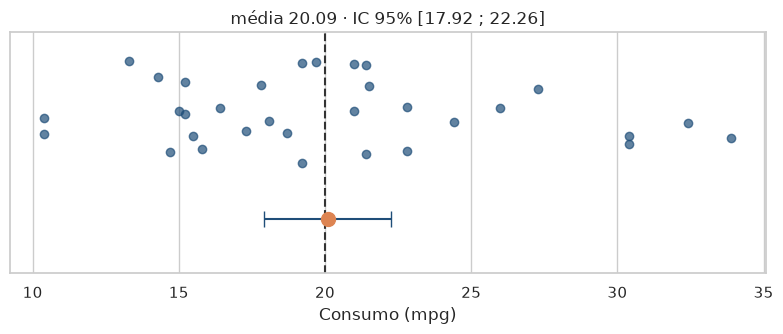

In [12]:
# Pontos, média e intervalo de confiança em relação a um valor de referência
def plot_mean_ci(values, ci, ref, xlabel, ax):
    jitter = np.random.default_rng(1).uniform(0.6, 1.4, len(values))
    ax.scatter(values, jitter, color="#1F4E79", alpha=.7)
    error = [[values.mean() - ci.low], [ci.high - values.mean()]]
    ax.errorbar(values.mean(), 0.2, xerr=error, fmt="o", color="#DD8452",
                ecolor="#1F4E79", capsize=6, markersize=10)
    ax.axvline(ref, color="#333333", linestyle="--")
    ax.set(xlabel=xlabel, yticks=[], ylim=(-0.2, 1.6),
           title=f"média {values.mean():.2f} · IC 95% [{ci.low:.2f} ; {ci.high:.2f}]")

fig, ax = plt.subplots(figsize=(8, 3.5))
plot_mean_ci(mpg, case1.confidence_interval(), target, "Consumo (mpg)", ax)
plt.tight_layout()
plt.show()

**Interpretação.** Os carros se espalham dos dois lados da meta, de 10 a
34 mpg. A média (ponto laranja) cai praticamente sobre a linha
tracejada, e o intervalo de confiança, de 17,9 a 22,3 mpg, contém a meta
com folga. Se a média real da frota fosse 20 mpg, diferenças iguais ou
maiores que a observada surgiriam em 93% das amostras
($p \approx 0{,}93$). Não rejeitamos $H_0$: não há evidência de que a
frota esteja fora da meta. Isso, porém, não prova que $\mu = 20$. Os
dados são apenas compatíveis com a meta, como também seriam com qualquer
valor dentro do intervalo.

## Caso 2. Teste *t* de Welch

> **Cenário**
>
> Uma equipe de biólogos de campo quer saber se machos e fêmeas de
> pinguins têm massas corporais (`body_mass`, em gramas) médias
> diferentes, um sinal de dimorfismo sexual. Cada grupo é formado por
> animais distintos.
>
> -   $H_0$: machos e fêmeas têm, em média, a mesma massa
>     ($\mu_1 = \mu_2$).
> -   $H_1$: as massas médias são diferentes ($\mu_1 \neq \mu_2$).

**Premissas do teste**

-   Observações independentes, dentro de cada grupo e entre os grupos.
-   Variável resposta numérica contínua.
-   Distribuição normal em cada grupo ou amostras grandes o bastante
    para o teorema central do limite.
-   As variâncias dos grupos **não** precisam ser iguais. É isso que
    distingue a versão de Welch do teste *t* clássico.

A base tem 344 pinguins, mas 11 não têm o sexo registrado. Ficamos com
os 333 restantes:

In [13]:
# Pinguins com sexo e massa registrados
penguins_sex = penguins.dropna(subset=["sex", "body_mass"])

males = penguins_sex.loc[penguins_sex["sex"] == "male", "body_mass"]
females = penguins_sex.loc[penguins_sex["sex"] == "female", "body_mass"]

O teste de Welch usa a variância de cada grupo separadamente. A tabela
traz a parcela $s^2/n$ de cada um, que mede a incerteza da média do
grupo:

In [14]:
# Resumo por grupo e parcelas do erro-padrão de Welch
welch_table = (
    penguins_sex
    .groupby("sex")
    .body_mass
    .agg(n="size", média="mean", dp="std")
    .assign(s2_n=lambda df: df["dp"] ** 2 / df["n"])
)

welch_table.round(1)

,n,média,dp,s2_n
sex,,,,
female,165,3862.3,666.2,2689.6
male,168,4545.7,787.6,3692.6


In [15]:
# Erro-padrão da diferença, estatística t e teste de Welch
se_diff = np.sqrt(welch_table["s2_n"].sum())
t_manual = (males.mean() - females.mean()) / se_diff

case2 = stats.ttest_ind(males, females, equal_var=False)

print(f"erro-padrão da diferença = {se_diff:.1f} g")
print(f"t calculado à mão = {t_manual:.2f}")
report("t de Welch", case2, stat="t")

erro-padrão da diferença = 79.9 g
t calculado à mão = 8.55
t de Welch: t = 8.555 · gl = 323.9 · p < 0.001 · IC 95% [526.25 ; 840.58]


Os machos pesam, em média, 4.546 g, e as fêmeas, 3.862 g: uma diferença
de 683 g. O erro-padrão da diferença é de cerca de 80 g, e a diferença
cabe 8,55 vezes nele. Os graus de liberdade, cerca de 324, vêm da
correção de Welch-Satterthwaite, que ajusta a curva *t* quando as
variâncias diferem.

Com mais de 160 animais por grupo, o teorema central do limite garante a
normalidade das médias. E as variâncias, diferem? O teste de **Levene**
verifica a homocedasticidade:

In [16]:
# Homocedasticidade, intervalo da diferença e sobreposição dos grupos
ci = case2.confidence_interval()

print(f"Levene: p = {stats.levene(males, females).pvalue:.3f}")
print(f"IC 95% da diferença: [{ci.low:.0f} ; {ci.high:.0f}] g")
print(f"fêmeas acima do macho médio: {(females > males.mean()).mean():.0%}")

Levene: p = 0.014
IC 95% da diferença: [526 ; 841] g
fêmeas acima do macho médio: 25%


O desvio-padrão dos machos (788 g) é maior que o das fêmeas (666 g), e o
Levene rejeita a igualdade de variâncias ($p \approx 0{,}014$). Esse é o
motivo para usar a versão de Welch. O intervalo de confiança de 95% da
diferença vai de 526 a 841 g, longe de zero.

O gráfico mostra cada pinguim e a média de cada grupo. Ele será
reutilizado no caso 4, por isso fica em uma função:

In [17]:
# Observações e média de cada grupo
def plot_group_means(data, x, y, order, ylabel, ax):
    sns.stripplot(data=data, x=x, y=y, order=order, ax=ax,
                  color="#1F4E79", alpha=.5, jitter=.25)
    means = data.groupby(x)[y].mean().reindex(order)
    ax.hlines(means, np.arange(len(order)) - .35, np.arange(len(order)) + .35,
              color="#DD8452", linewidth=3)
    ax.set(xlabel="", ylabel=ylabel)

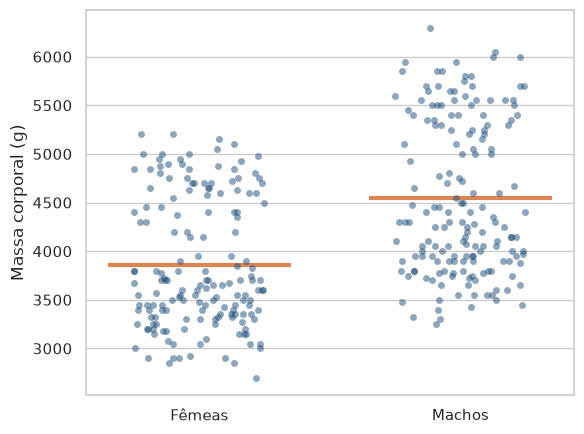

In [18]:
fig, ax = plt.subplots(figsize=(6, 4.5))
plot_group_means(penguins_sex, "sex", "body_mass", ["female", "male"],
                 "Massa corporal (g)", ax)
ax.set_xticks([0, 1], ["Fêmeas", "Machos"])
plt.tight_layout()
plt.show()

**Interpretação.** Os dois grupos se sobrepõem bastante: cerca de 25%
das fêmeas pesam mais que o macho médio. Ainda assim, a média dos machos
fica bem acima da média das fêmeas. Se machos e fêmeas tivessem a mesma
massa média, uma diferença de 683 g seria praticamente impossível por
acaso ($p < 0{,}001$). Rejeitamos $H_0$: há evidência de dimorfismo
sexual, com machos mais pesados. Note que o teste fala de **médias**.
Ele não afirma que todo macho é mais pesado que toda fêmea.

### Existe dimorfismo dentro de cada espécie?

A base reúne três espécies de pinguim, com tamanhos bem diferentes. Ao
comparar todos os machos com todas as fêmeas, misturamos essa variação
entre espécies com a variação entre os sexos. Vejamos o desvio-padrão da
massa em cada combinação de espécie e sexo:

In [19]:
# Média e desvio-padrão da massa por espécie e sexo
(
    penguins_sex
    .groupby(["species", "sex"])
    .body_mass
    .agg(["size", "mean", "std"])
    .round(0)
)

size    mean    std
species   sex                        
Adelie    female    73  3369.0  269.0
          male      73  4043.0  347.0
Chinstrap female    34  3527.0  285.0
          male      34  3939.0  362.0
Gentoo    female    58  4680.0  282.0
          male      61  5485.0  313.0

O boxplot mostra a mesma informação por espécie, com os sexos lado a
lado:

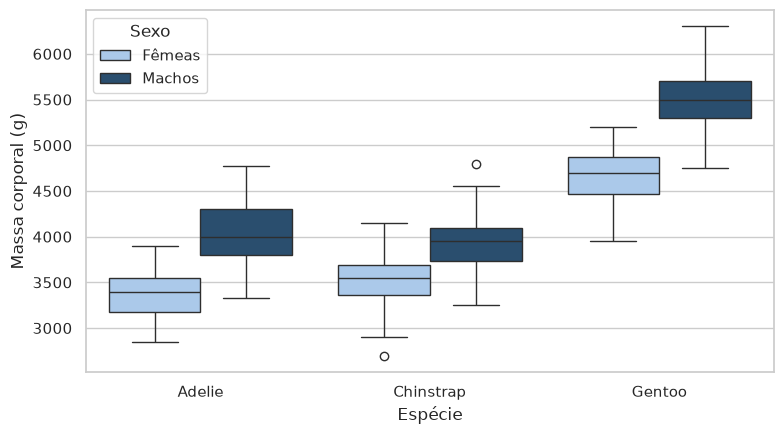

In [20]:
# Massa corporal por espécie e sexo
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.boxplot(
    data=penguins_sex,
    x="species",
    y="body_mass",
    order=["Adelie", "Chinstrap", "Gentoo"],
    hue="sex",
    hue_order=["female", "male"],
    palette={"female": "#A1C9F4", "male": "#1F4E79"},
    ax=ax,
)
ax.set(xlabel="Espécie", ylabel="Massa corporal (g)")

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Fêmeas", "Machos"], title="Sexo")

plt.tight_layout()
plt.show()

Em todas as espécies, a caixa dos machos fica acima da caixa das fêmeas.
As caixas, porém, são bem mais curtas do que a variação total da massa,
porque a espécie pesa mais que o sexo: o macho Adelie típico, com cerca
de 4.000 g, é mais leve que a fêmea Gentoo típica, com cerca de 4.700 g.
Dentro de cada espécie, o desvio-padrão fica entre cerca de 270 e 360 g.
No teste geral, ele passava de 660 g, porque cada grupo misturava
pinguins pequenos e grandes. Repetimos então o teste de Welch
separadamente em cada espécie:

In [21]:
# Teste de Welch dentro de cada espécie
for species, group in penguins_sex.groupby("species"):
    male = group.loc[group["sex"] == "male", "body_mass"]
    female = group.loc[group["sex"] == "female", "body_mass"]
    report(species, stats.ttest_ind(male, female, equal_var=False), stat="t")

Adelie: t = 13.126 · gl = 135.7 · p < 0.001 · IC 95% [573.01 ; 776.30]
Chinstrap: t = 5.208 · gl = 62.58 · p < 0.001 · IC 95% [253.74 ; 569.79]
Gentoo: t = 14.761 · gl = 116.6 · p < 0.001 · IC 95% [697.08 ; 913.11]


O dimorfismo aparece nas três espécies, com $p < 0{,}001$ em todas. Em
Adelie e Gentoo, a estatística *t* fica bem maior que a do teste geral
(8,6), mesmo com menos animais, porque o erro-padrão cai de cerca de 80
g para cerca de 50 g. A diferença também varia entre as espécies: os
machos Gentoo pesam cerca de 800 g a mais que as fêmeas, e os machos
Chinstrap, cerca de 410 g. Separar os grupos torna a pergunta mais
honesta e o teste mais preciso, uma ideia que retomaremos ao estudar
modelos com mais de uma variável explicativa.

## Caso 3. Teste *t* pareado

> **Cenário**
>
> Em um ensaio clínico, os mesmos 10 pacientes testaram dois soníferos,
> um em cada período, e foram medidas as horas extras de sono (`extra`).
> O médico quer saber se a droga 2 rende mais horas de sono que a droga
> 1.
>
> -   $H_0$: em média, a droga 2 não muda as horas de sono em relação à
>     droga 1 ($\mu_D = 0$).
> -   $H_1$: em média, as horas de sono mudam entre as drogas
>     ($\mu_D \neq 0$).

**Premissas do teste**

-   Cada par de medidas vem da mesma unidade, no caso o mesmo paciente.
-   Os pares são independentes entre si.
-   Variável resposta numérica contínua.
-   As diferenças dentro de cada par, $D_i = X_{2i} - X_{1i}$, seguem
    aproximadamente uma distribuição normal.

A base `sleep` está no formato longo: uma linha por paciente e droga.
Reorganizamos para uma linha por paciente e calculamos a diferença:

In [22]:
# Uma linha por paciente, com a diferença entre as drogas
sleep_wide = (
    sleep
    .pivot(index="ID", columns="group", values="extra")
    .rename(columns={1: "droga_1", 2: "droga_2"})
    .assign(D=lambda df: df["droga_2"] - df["droga_1"])
)

sleep_wide

group,droga_1,droga_2,D
ID,,,
1,0.7,1.9,1.2
2,-1.6,0.8,2.4
3,-0.2,1.1,1.3
4,-1.2,0.1,1.3
5,-0.1,-0.1,0.0
6,3.4,4.4,1.0
7,3.7,5.5,1.8
8,0.8,1.6,0.8
9,0.0,4.6,4.6


A partir daqui, as colunas originais saem de cena. O teste pareado é um
teste *t* de uma amostra sobre a coluna `D`, com $\mu_0 = 0$:

$$
t = \frac{\bar{D} - 0}{s_D / \sqrt{n}}
$$

In [23]:
# Teste t pareado e o mesmo teste ignorando o pareamento
case3 = stats.ttest_rel(sleep_wide["droga_2"], sleep_wide["droga_1"])
unpaired = stats.ttest_ind(sleep_wide["droga_2"], sleep_wide["droga_1"])

pd.DataFrame(
    {"t": [case3.statistic, unpaired.statistic], "p": [case3.pvalue, unpaired.pvalue]},
    index=["pareado", "ignorando o pareamento"],
).round(4)

,t,p
pareado,4.0621,0.0028
ignorando o pareamento,1.8608,0.0792


A média das diferenças é de 1,58 h, com desvio-padrão de 1,23 h. O teste
pareado dá $t = 4{,}06$ com 9 graus de liberdade e $p \approx 0{,}003$.
Com os **mesmos dados**, tratados como dois grupos independentes, o
*p*-valor sobe para 0,079, e a diferença deixa de ser significante.

O motivo aparece no gráfico. À esquerda, cada linha liga as duas medidas
de um paciente. À direita, cada ponto é a diferença de um paciente, com
a média e o intervalo de confiança:

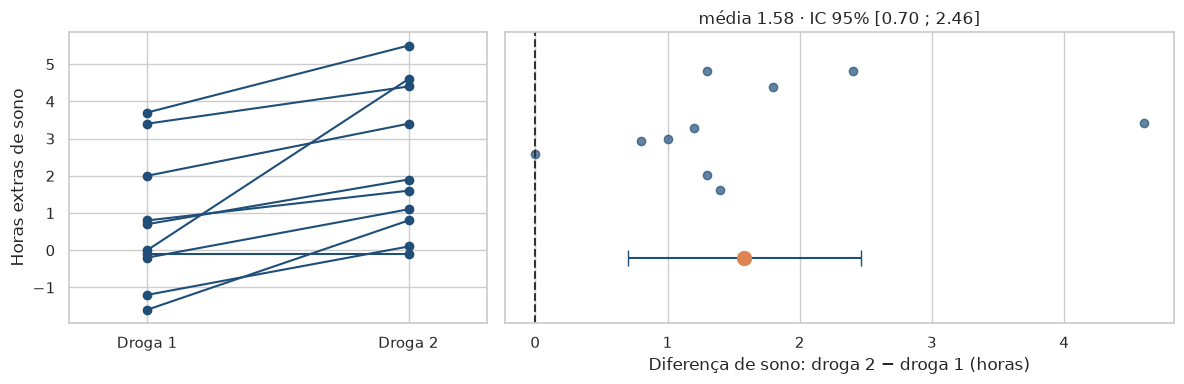

In [24]:
# Linhas por paciente e diferenças com intervalo de confiança
fig, axes = plt.subplots(1, 2, figsize=(12, 4), width_ratios=[1, 1.6])

axes[0].plot([0, 1], sleep_wide[["droga_1", "droga_2"]].T, color="#1F4E79", marker="o")
axes[0].set(xticks=[0, 1], xticklabels=["Droga 1", "Droga 2"], xlim=(-.3, 1.3),
            ylabel="Horas extras de sono")

plot_mean_ci(sleep_wide["D"], case3.confidence_interval(), 0,
             "Diferença de sono: droga 2 − droga 1 (horas)", axes[1])
plt.tight_layout()
plt.show()

Os pacientes são muito diferentes entre si: alguns dormem bem com
qualquer droga, outros dormem pouco. A correlação entre as duas medidas
de cada paciente é de cerca de 0,80. Vistos como dois grupos soltos, os
pontos se misturam, e a variação **entre pacientes** esconde o efeito.
Olhando paciente a paciente, o padrão aparece: as linhas sobem em 9 dos
10 casos, e nenhum paciente piora. O pareamento cancela a variação de
base de cada pessoa e isola o efeito da droga.

Há, porém, uma ressalva. Com apenas 10 diferenças, a normalidade pesa
mais:

In [25]:
# Normalidade das diferenças e alternativa não paramétrica
report("Shapiro-Wilk das diferenças", stats.shapiro(sleep_wide["D"]), stat="W")
report("Wilcoxon", stats.wilcoxon(sleep_wide["D"]), stat="T")

Shapiro-Wilk das diferenças: W = 0.830 · p = 0.033
Wilcoxon: T = 0.000 · p = 0.004


O Shapiro-Wilk rejeita a normalidade das diferenças
($p \approx 0{,}03$), em boa parte por causa do paciente com ganho de
4,6 h. O teste de Wilcoxon dos postos sinalizados, a alternativa não
paramétrica ao *t* pareado, chega à mesma conclusão
($p \approx 0{,}004$).

**Interpretação.** Quase todos os pacientes estão à direita da linha de
zero, e o intervalo da média, de 0,70 a 2,46 h, não toca nela. Se as
duas drogas fossem equivalentes, um ganho médio de 1,58 h surgiria em
apenas 0,3% dos ensaios. Rejeitamos $H_0$: nos mesmos pacientes, a droga
2 rende em média cerca de 1,6 h a mais de sono que a droga 1.

## Caso 4. ANOVA one-way

> **Cenário**
>
> Um botânico mede flores de três espécies de íris e quer saber se o
> comprimento médio da sépala (`sepal_length`) é o mesmo nas três, antes
> de usá-lo para diferenciá-las.
>
> -   $H_0$: as três espécies têm o mesmo comprimento médio
>     ($\mu_1 = \mu_2 = \mu_3$).
> -   $H_1$: pelo menos uma espécie tem média diferente.

**Premissas do teste**

-   Observações independentes, dentro de cada grupo e entre os grupos.
-   Variável resposta numérica contínua.
-   Resíduos aproximadamente normais em cada grupo.
-   Variâncias iguais entre os grupos (homocedasticidade).

Por que não comparar as espécies duas a duas com três testes *t*? Porque
cada teste acrescenta uma chance de falso positivo, como demonstraremos
ao fim deste caso. A ANOVA responde à pergunta com **um único teste** e
mantém o $\alpha$ em 5%.

A ideia da ANOVA é comparar duas fontes de variação. Se as médias das
espécies se afastam muito da média geral, em relação à variação natural
dentro de cada espécie, a estatística *F* fica grande:

$$
F = \frac{MQG}{MQR} = \frac{SQG / (k - 1)}{SQR / (N - k)}
$$

Aqui, $SQG$ é a soma de quadrados **entre** grupos, $SQR$ a soma de
quadrados **dentro** dos grupos (resíduos), $k$ o número de grupos e $N$
o total de observações. Calculamos a tabela da ANOVA passo a passo:

In [26]:
# Tabela da ANOVA calculada passo a passo
grand_mean = iris["sepal_length"].mean()

by_species = (
    iris
    .groupby("species")
    .sepal_length
    .agg(n="size", média="mean", dp="std")
)

ss_between = (by_species["n"] * (by_species["média"] - grand_mean) ** 2).sum()

ss_within = ((by_species["n"] - 1) * by_species["dp"] ** 2).sum()

k, N = len(by_species), len(iris)

In [27]:
pd.DataFrame(
    {"SQ": [ss_between, ss_within], "gl": [k - 1, N - k]},
    index=["entre espécies", "dentro (resíduos)"],
).assign(MQ=lambda df: df["SQ"] / df["gl"]).round(3)

,SQ,gl,MQ
entre espécies,63.212,2,31.606
dentro (resíduos),38.956,147,0.265


O quadrado médio entre espécies (31,61) é cerca de 119 vezes o quadrado
médio dentro das espécies (0,265). Conferimos com o SciPy e, como a
ANOVA só diz que **alguma** média difere, usamos o teste de Tukey para
descobrir **quais**:

In [28]:
# ANOVA, comparações de Tukey e homocedasticidade
setosa, versicolor, virginica = [
    group["sepal_length"] for _, group in iris.groupby("species")
]

anova = stats.f_oneway(setosa, versicolor, virginica)

report("ANOVA", anova, stat="F", df=(k - 1, N - k))
report("Levene", stats.levene(setosa, versicolor, virginica))

ANOVA: F = 119.265 · gl = (2, 147) · p < 0.001
Levene: estatística = 6.353 · p = 0.002


In [29]:
# Comparações de Tukey
print(stats.tukey_hsd(setosa, versicolor, virginica))

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.930     0.000    -1.174    -0.686
 (0 - 2)     -1.582     0.000    -1.826    -1.338
 (1 - 0)      0.930     0.000     0.686     1.174
 (1 - 2)     -0.652     0.000    -0.896    -0.408
 (2 - 0)      1.582     0.000     1.338     1.826
 (2 - 1)      0.652     0.000     0.408     0.896



A ANOVA dá $F \approx 119{,}3$ com $(2, 147)$ graus de liberdade e
$p < 0{,}001$. O Tukey indica que os três pares diferem, com diferenças
de 0,65 a 1,58 cm e todos os *p*-valores abaixo de 0,001. A fração da
variação total explicada pela espécie, $\eta^2 = SQG / (SQG + SQR)$, é
de cerca de 0,62.

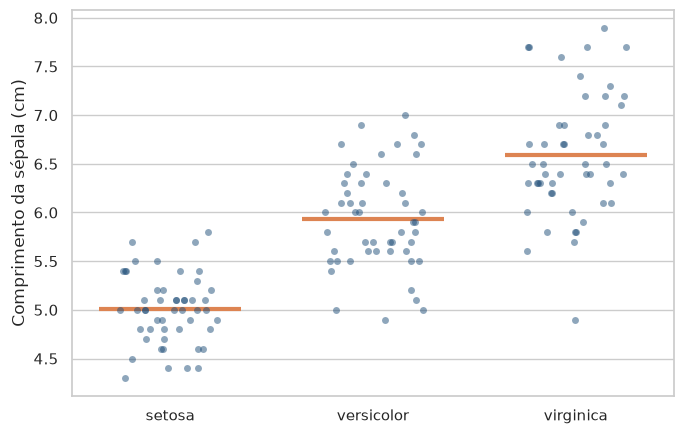

In [30]:
# Comprimento da sépala por espécie
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_group_means(iris, "species", "sepal_length", ["setosa", "versicolor", "virginica"],
                 "Comprimento da sépala (cm)", ax)
plt.tight_layout()
plt.show()

**Interpretação.** As médias sobem de setosa (5,01 cm) para versicolor
(5,94 cm) e virginica (6,59 cm), e a distância entre elas é grande em
relação à dispersão dentro de cada espécie. Se as espécies tivessem a
mesma sépala média, diferenças desse tamanho seriam praticamente
impossíveis por acaso. Rejeitamos $H_0$: o comprimento da sépala
distingue as três espécies, e todos os pares diferem entre si.

Fica uma ressalva. O teste de Levene rejeita a igualdade de variâncias
($p \approx 0{,}002$): a dispersão cresce de setosa para virginica.
Nesse caso, uma alternativa mais segura é a ANOVA de Welch, seguida do
teste de Games-Howell. Com diferenças tão grandes, a conclusão não muda.

### Por que não rodar múltiplos testes *t* de Student?

Com três espécies, seria tentador fazer três testes *t*: setosa ×
versicolor, setosa × virginica e versicolor × virginica. O problema é
que cada teste tem 5% de chance de um falso positivo, e essas chances se
acumulam. A probabilidade de errar **pelo menos uma vez** em $c$
comparações independentes é:

$$
\alpha_{\text{conjunto}} = 1 - (1 - \alpha)^c
$$

Com $k$ grupos, há $c = k(k-1)/2$ pares. Com $\alpha = 0{,}05$:

| Grupos ($k$) | Comparações ($c$) | Chance de pelo menos um falso positivo |
|--------------|-------------------|----------------------------------------|
| 2            | 1                 | 5%                                     |
| 3            | 3                 | 14%                                    |
| 4            | 6                 | 26%                                    |
| 5            | 10                | 40%                                    |

Podemos verificar isso com a própria `iris`. Embaralhando os rótulos de
espécie, como no teste de permutação da Aula 7, criamos um mundo em que
**sabemos** que $H_0$ é verdadeira: as “espécies” passam a ser grupos
sorteados ao acaso. Repetimos o sorteio 2.000 vezes e, em cada um,
registramos se os três testes *t* encontraram alguma diferença e se a
ANOVA encontrou:

In [31]:
# Falsos positivos com três testes t e com uma ANOVA, sob H0 verdadeira
rng = np.random.default_rng(2026)
values = iris["sepal_length"].to_numpy()
labels = iris["species"].to_numpy()
pairs = [(0, 1), (0, 2), (1, 2)]

any_t, anova_rejects = [], []
for _ in range(2_000):
    shuffled = rng.permutation(labels)
    groups = [values[shuffled == species] for species in np.unique(labels)]
    p_values = [stats.ttest_ind(groups[a], groups[b]).pvalue for a, b in pairs]
    any_t.append(min(p_values) <= .05)
    anova_rejects.append(stats.f_oneway(*groups).pvalue <= .05)

print(f"três testes t: algum falso positivo em {np.mean(any_t):.1%} dos sorteios")
print(f"uma ANOVA: falso positivo em {np.mean(anova_rejects):.1%} dos sorteios")

três testes t: algum falso positivo em 13.4% dos sorteios
uma ANOVA: falso positivo em 5.0% dos sorteios


Com três testes *t*, cerca de 13% dos sorteios produziram pelo menos uma
“diferença significante”, embora nenhuma exista. Com a ANOVA, a taxa
fica em 5%, exatamente o $\alpha$ escolhido. O valor simulado fica um
pouco abaixo dos 14% da fórmula porque os três testes compartilham
grupos e, por isso, não são independentes.

Por isso a sequência correta é **ANOVA primeiro, post-hoc depois**. A
ANOVA decide, com um único teste, se existe alguma diferença. Só então o
teste de Tukey identifica quais pares diferem, ajustando os *p*-valores
para que o conjunto de comparações mantenha o $\alpha$ em 5%.

## Caso 5. Correlação de Pearson

> **Cenário**
>
> Um engenheiro quer entender se carros mais pesados (`wt`, em milhares
> de libras) tendem a gastar mais combustível (`mpg`), e quão forte é
> essa relação, antes de propor um projeto mais leve.
>
> -   $H_0$: não há relação linear entre peso e consumo ($\rho = 0$).
> -   $H_1$: existe relação linear entre peso e consumo ($\rho \neq 0$).

**Premissas do teste**

-   Pares de observações independentes entre si.
-   As duas variáveis são numéricas contínuas.
-   A relação entre elas é linear.
-   Normalidade bivariada e ausência de valores atípicos influentes.

O coeficiente de Pearson mede o quanto duas variáveis numéricas andam
juntas **em linha reta**. O numerador soma os produtos dos desvios: é
positivo quando valores altos de uma variável acompanham valores altos
da outra. O denominador padroniza o resultado e o prende entre $-1$ e
$+1$:

$$
r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \cdot \sum (y_i - \bar{y})^2}}
$$

In [32]:
# Coeficiente de Pearson pela fórmula e pelo SciPy
dx = mtcars["wt"] - mtcars["wt"].mean()
dy = mtcars["mpg"] - mtcars["mpg"].mean()

r_manual = (dx * dy).sum() / np.sqrt((dx ** 2).sum() * (dy ** 2).sum())
case5 = stats.pearsonr(mtcars["wt"], mtcars["mpg"])

print(f"r calculado à mão = {r_manual:.3f}")
report("Pearson", case5, stat="r")

r calculado à mão = -0.868
Pearson: r = -0.868 · p < 0.001 · IC 95% [-0.93 ; -0.74]


O coeficiente vale $r \approx -0{,}87$, com $p < 0{,}001$. O sinal
negativo indica a direção: mais peso, menos milhas por galão. O tamanho
indica a força. Como referência, valores de $|r|$ abaixo de 0,3 costumam
ser descritos como fracos, entre 0,3 e 0,5 como moderados e acima de 0,5
como fortes.

O coeficiente tem duas propriedades úteis. Ele é **simétrico**:
$r(\text{peso}, \text{consumo}) = r(\text{consumo}, \text{peso})$. E é
**invariante** a mudanças de unidade. Convertendo o peso para
quilogramas, o resultado não muda:

In [33]:
# O coeficiente não depende da unidade de medida
r_kg = stats.pearsonr(mtcars["wt"] * 453.6, mtcars["mpg"]).statistic

print(f"r com o peso em kg = {r_kg:.3f}")

r com o peso em kg = -0.868


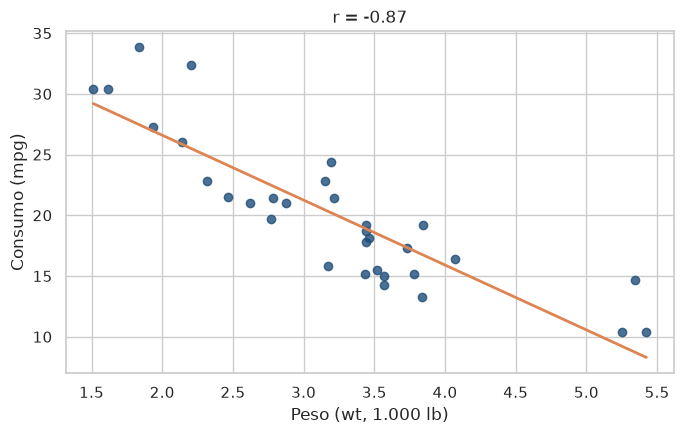

In [34]:
# Consumo versus peso, com a reta de mínimos quadrados
slope, intercept = np.polyfit(mtcars["wt"], mtcars["mpg"], deg=1)
grid = np.linspace(mtcars["wt"].min(), mtcars["wt"].max(), 100)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(mtcars["wt"], mtcars["mpg"], color="#1F4E79", alpha=.8)
ax.plot(grid, intercept + slope * grid, color="#DD8452", linewidth=2)
ax.set(title=f"r = {case5.statistic:.2f}", xlabel="Peso (wt, 1.000 lb)",
       ylabel="Consumo (mpg)")
plt.tight_layout()
plt.show()

**Interpretação.** Os pontos descem da esquerda para a direita e ficam
próximos da reta. Se peso e consumo não tivessem relação linear, um *r*
tão forte seria praticamente impossível por acaso. Rejeitamos $H_0$:
carros mais pesados tendem a fazer menos milhas por galão.

Dois limites merecem atenção. Pearson só enxerga relações **lineares**:
uma relação em forma de U pode ter $r \approx 0$ e, para relações
monotônicas mas curvas, o coeficiente de Spearman é mais adequado. E
correlação **não é causalidade**: o coeficiente mede associação, e a
causa exige um mecanismo ou um experimento.

### A transformação log melhora a correlação?

Ainda no `mtcars`, carros mais potentes (`hp`) tendem a consumir mais
combustível (menos `mpg`). Como o coeficiente de Pearson mede apenas a
parte **linear** da relação, ele perde força quando os pontos formam uma
curva. A transformação log, vista na Aula 6, pode corrigir isso.
Calculamos o Pearson com a potência na escala original e em log:

In [35]:
# Pearson com a potência na escala original e em log
log_hp = np.log(mtcars["hp"])

report("Pearson com hp", stats.pearsonr(mtcars["hp"], mtcars["mpg"]), stat="r")
report("Pearson com log(hp)", stats.pearsonr(log_hp, mtcars["mpg"]), stat="r")

Pearson com hp: r = -0.776 · p < 0.001 · IC 95% [-0.89 ; -0.59]
Pearson com log(hp): r = -0.849 · p < 0.001 · IC 95% [-0.92 ; -0.71]


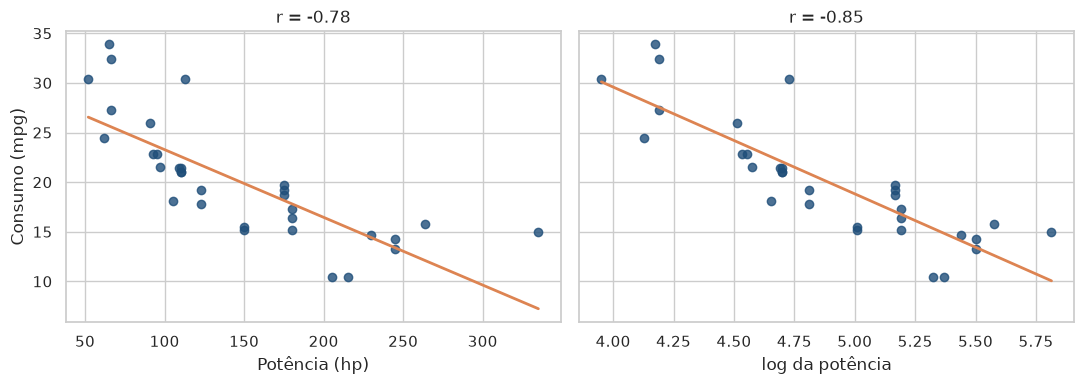

In [36]:
# Consumo versus potência, na escala original e com a potência em log
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, x, xlabel in zip(
    axes,
    [mtcars["hp"], log_hp],
    ["Potência (hp)", "log da potência"],
):
    slope, intercept = np.polyfit(x, mtcars["mpg"], deg=1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.scatter(x, mtcars["mpg"], color="#1F4E79", alpha=.8)
    ax.plot(grid, intercept + slope * grid, color="#DD8452", linewidth=2)
    ax.set(xlabel=xlabel, title=f"r = {stats.pearsonr(x, mtcars['mpg']).statistic:.2f}")

axes[0].set_ylabel("Consumo (mpg)")
plt.tight_layout()
plt.show()

Na escala original, à esquerda, o consumo cai rápido entre os carros de
baixa potência e depois se estabiliza. Os pontos formam uma curva e
ficam acima da reta nos dois extremos e abaixo dela no meio. O log
comprime os valores altos de potência e estica os baixos, e os pontos
passam a seguir melhor uma reta, à direita. Com isso, o coeficiente sobe
de $r \approx -0{,}78$ para $r \approx -0{,}85$.

A relação entre potência e consumo é a mesma nos dois gráficos. O que
muda é a escala em que a medimos. Quando a relação é curva, transformar
uma das variáveis pode torná-la mais linear e, assim, mais bem capturada
pelo coeficiente de Pearson.

## Caso 6. Teste *Z* de duas proporções

> **Cenário**
>
> Um historiador analisa o naufrágio do Titanic: a regra “mulheres e
> crianças primeiro” deixou marca nos números? A sobrevivência
> (`survived`) foi diferente entre mulheres e homens (`sex`)?
>
> -   $H_0$: mulheres e homens tiveram a mesma taxa de sobrevivência
>     ($p_1 = p_2$).
> -   $H_1$: as taxas de sobrevivência foram diferentes
>     ($p_1 \neq p_2$).

**Premissas do teste**

-   Variável resposta binária: sucesso ou fracasso.
-   Observações independentes, dentro de cada grupo e entre os grupos.
-   Amostras grandes o bastante para a aproximação normal:
    $n \cdot \hat{p} \geq 5$ e $n \cdot (1 - \hat{p}) \geq 5$ em cada
    grupo.

A resposta agora é **binária**: sobreviveu (1) ou não (0). A média de
uma variável 0/1 é a proporção de uns, e a comparação passa a ser entre
proporções. Sob $H_0$, as duas taxas são iguais, e a melhor estimativa
dessa taxa comum é a **proporção combinada** $\hat{p}$, que junta os
dois grupos:

$$
Z = \frac{\hat{p}_1 - \hat{p}_2}{\sqrt{\hat{p}(1 - \hat{p})\left(\dfrac{1}{n_1} + \dfrac{1}{n_2}\right)}}
\qquad
\hat{p} = \frac{x_1 + x_2}{n_1 + n_2}
$$

In [37]:
# Sobreviventes, total e proporção por sexo
by_sex = (
    titanic
    .groupby("sex")
    .survived
    .agg(sobreviventes="sum", n="size")
    .assign(
        nao_sobreviventes=lambda df: df["n"] - df["sobreviventes"],
        proporcao=lambda df: df["sobreviventes"] / df["n"],
    )
)

by_sex.round(3)

,sobreviventes,n,nao_sobreviventes,proporcao
sex,,,,
female,233,314,81,0.742
male,109,577,468,0.189


Sobreviveram 74,2% das mulheres (233 de 314) e 18,9% dos homens (109 de
577). A menor contagem da condição é 81, muito acima de 5. Calculamos
*Z* pela fórmula e com o `statsmodels`:

In [38]:
# Estatística Z pela fórmula e pelo statsmodels
p_pooled = by_sex["sobreviventes"].sum() / by_sex["n"].sum()
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1 / by_sex["n"]).sum())
diff = by_sex.loc["female", "proporcao"] - by_sex.loc["male", "proporcao"]
z_manual = diff / se_pooled

case6 = proportions_ztest(by_sex["sobreviventes"], by_sex["n"])

print(f"proporção combinada = {p_pooled:.3f}")
print(f"Z calculado à mão = {z_manual:.2f}")
report("Z de duas proporções", case6, stat="Z")

proporção combinada = 0.384
Z calculado à mão = 16.22
Z de duas proporções: Z = 16.219 · p < 0.001


A proporção combinada é de 38,4%, a taxa geral de sobrevivência. A
estatística vale $Z \approx 16{,}2$: a diferença entre as taxas equivale
a mais de 16 erros-padrão. O gráfico mostra cada taxa com seu intervalo
de confiança de 95%:

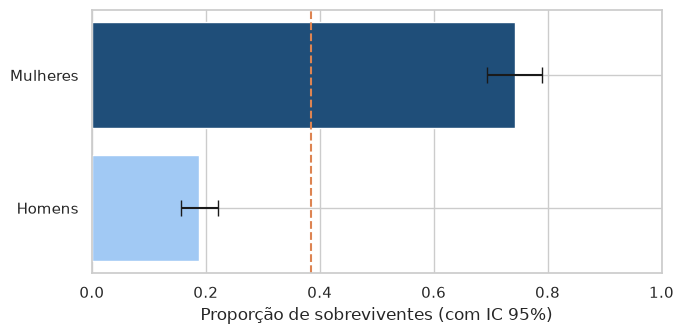

In [39]:
# Proporção de sobreviventes por sexo, com intervalo de confiança
low, high = proportion_confint(by_sex["sobreviventes"], by_sex["n"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(["Homens", "Mulheres"], by_sex.loc[["male", "female"], "proporcao"],
        xerr=[(by_sex["proporcao"] - low)[["male", "female"]],
              (high - by_sex["proporcao"])[["male", "female"]]],
        color=["#A1C9F4", "#1F4E79"], capsize=6)
ax.axvline(p_pooled, color="#DD8452", linestyle="--")
ax.set(xlim=(0, 1), xlabel="Proporção de sobreviventes (com IC 95%)")
plt.tight_layout()
plt.show()

**Interpretação.** A barra das mulheres é quase quatro vezes a dos
homens, e os intervalos ficam muito longe um do outro e da taxa geral de
38% (linha tracejada). Se mulheres e homens tivessem a mesma chance de
sobreviver, 55 pontos percentuais de diferença seriam impossíveis por
acaso ($p < 0{,}001$). Rejeitamos $H_0$: a regra “mulheres e crianças
primeiro” aparece nos dados.

## Caso 7. Qui-quadrado de independência

> **Cenário**
>
> O mesmo historiador pergunta se a classe da passagem (`pclass`: 1ª, 2ª
> ou 3ª) teve relação com quem sobreviveu (`survived`), ou se a
> sobrevivência foi independente da classe.
>
> -   $H_0$: a sobrevivência não depende da classe. As variáveis são
>     independentes.
> -   $H_1$: a sobrevivência está associada à classe.

**Premissas do teste**

-   As duas variáveis são categóricas.
-   Observações independentes, cada uma contada em uma única célula da
    tabela.
-   Frequência esperada de pelo menos 5 em pelo menos 80% das células e
    nenhuma abaixo de 1. Quando essa condição falha, usa-se o teste
    exato de Fisher.

Com duas variáveis categóricas, os dados se resumem a uma **tabela de
contingência**, que conta os passageiros em cada combinação de classe e
desfecho:

In [40]:
# Tabela de contingência: classe por desfecho
observed = pd.crosstab(titanic["pclass"], titanic["survived"])

observed

survived,0,1
pclass,,
1,80,136
2,97,87
3,372,119


O teste compara essas contagens observadas ($O$) com as que
**esperaríamos se a classe não tivesse nada a ver com a sobrevivência**
($E$). Sob independência, a contagem esperada de cada célula é o total
da linha vezes o total da coluna, dividido pelo total geral. A
estatística soma as discrepâncias padronizadas de todas as células:

$$
\chi^2 = \sum \frac{(O - E)^2}{E}
\qquad
\text{gl} = (\text{linhas} - 1)(\text{colunas} - 1)
$$

In [41]:
# Qui-quadrado, frequências esperadas e parcela de cada célula
case7 = stats.chi2_contingency(observed)

expected = pd.DataFrame(
    case7.expected_freq, index=observed.index, columns=observed.columns
)
contributions = (observed - expected) ** 2 / expected

print(f"χ² = {case7.statistic:.2f}, gl = {case7.dof}, p = {case7.pvalue:.1e}")
pd.concat({"esperado": expected, "(O−E)²/E": contributions}, axis=1).round(1)

χ² = 102.89, gl = 2, p = 4.5e-23


esperado        (O−E)²/E      
survived        0      1        0     1
pclass                                 
1           133.1   82.9     21.2  34.0
2           113.4   70.6      2.4   3.8
3           302.5  188.5     15.9  25.6

A estatística vale $\chi^2 \approx 102{,}9$, com 2 graus de liberdade e
$p < 0{,}001$. A menor frequência esperada é 70,6, e a condição de
aplicação é atendida com folga. As parcelas mostram **onde** está o
desvio: as maiores contribuições vêm da 1ª classe, que sobreviveu muito
mais que o esperado, e da 3ª, que sobreviveu muito menos.

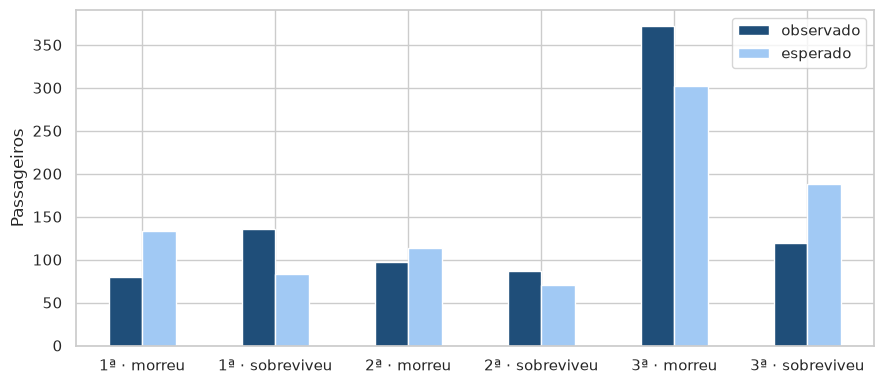

In [42]:
# Contagens observadas e esperadas sob independência
comparison = (
    pd.concat(
        {"observado": observed.stack(), "esperado": expected.stack()},
        axis=1,
    )
    .rename(index={0: "morreu", 1: "sobreviveu"}, level="survived")
)

fig, ax = plt.subplots(figsize=(9, 4))
comparison.plot.bar(ax=ax, color=["#1F4E79", "#A1C9F4"], rot=0)
ax.set_xticklabels([f"{c}ª · {d}" for c, d in comparison.index])
ax.set(xlabel="", ylabel="Passageiros")
plt.tight_layout()
plt.show()

**Interpretação.** Se classe e sobrevivência fossem independentes, as
barras escuras e claras teriam a mesma altura em cada par. Em vez disso,
a 1ª classe tem mais sobreviventes que o esperado (136 contra 83), e a
3ª classe tem muito menos (119 contra 188). A taxa de sobrevivência cai
de 63% na 1ª classe para 47% na 2ª e 24% na 3ª. Um desequilíbrio desse
tamanho seria praticamente impossível por acaso. Rejeitamos $H_0$: a
chance de sobreviver dependeu da classe de embarque. O V de Cramér, uma
medida da força da associação entre 0 e 1, vale cerca de 0,34, uma
associação moderada.

> **Z e qui-quadrado: o mesmo teste em tabelas 2 × 2**
>
> O teste *Z* do caso 6 também pode ser escrito como um qui-quadrado
> sobre a tabela sexo × sobrevivência, que tem 2 linhas e 2 colunas.
> Nesse caso particular, $Z^2 = \chi^2$: $16{,}2^2 \approx 263$. As duas
> abordagens dão o mesmo *p*-valor. O qui-quadrado tem a vantagem de se
> estender a tabelas maiores, como a da classe, com três linhas.

# 5. Quando as premissas falham

Se as premissas não se sustentam, troca-se o teste. As alternativas não
paramétricas trabalham, em geral, com **postos**: a posição de cada
valor na ordenação, em vez do valor em si. Isso as torna robustas a
assimetria e a valores atípicos.

| Paramétrico | Alternativa não paramétrica | Como funciona |
|------------------------|------------------------|------------------------|
| *t* de duas amostras | Mann-Whitney | Compara a soma dos postos dos dois grupos |
| *t* pareado | Wilcoxon dos postos sinalizados | Postos das diferenças, com sinal |
| ANOVA one-way | Kruskal-Wallis | Postos em três ou mais grupos |
| Pearson | Spearman | Correlação dos postos: capta relações monotônicas |
| Qualquer um | Permutação | Distribuição nula por embaralhamento (Aula 7) |

Amostras com menos de 10 observações, assimetria forte, valores atípicos
extremos ou escala ordinal são sinais para trocar o teste. O preço é
perder um pouco de poder nas situações em que as premissas valeriam.

# 6. Guia rápido

| Pergunta | Teste | Função |
|------------------------|------------------------|------------------------|
| A média difere de uma meta? | *t* de uma amostra | `stats.ttest_1samp` |
| Dois grupos independentes têm a mesma média? | *t* de Welch | `stats.ttest_ind(..., equal_var=False)` |
| A mesma unidade muda entre dois momentos? | *t* pareado | `stats.ttest_rel` |
| Três ou mais grupos têm a mesma média? | ANOVA + Tukey | `stats.f_oneway`, `stats.tukey_hsd` |
| Duas variáveis contínuas têm relação linear? | Pearson | `stats.pearsonr` |
| Dois grupos têm a mesma proporção? | *Z* de duas proporções | `proportions_ztest` |
| Duas variáveis categóricas são independentes? | Qui-quadrado | `stats.chi2_contingency` |
| Os dados são normais? | Q-Q plot + Shapiro-Wilk | `stats.probplot`, `stats.shapiro` |
| As variâncias são iguais? | Levene | `stats.levene` |

## Síntese

1.  **Paramétrico.** A distribuição nula vem da teoria (*t*, *F*, *Z* ou
    $\chi^2$), em troca de premissas.
2.  **Premissas.** Antes do teste, verifique normalidade,
    homocedasticidade e independência. O Q-Q plot e o Shapiro-Wilk se
    complementam.
3.  **Escolha.** O objetivo, a escala da variável e o delineamento
    determinam o teste.
4.  **Pareamento.** Ignorar o pareamento infla o erro-padrão: no
    `sleep`, o *p*-valor foi de 0,003 para 0,079.
5.  **Muitos grupos.** Com três ou mais grupos, use a ANOVA seguida de
    um teste post-hoc, nunca uma série de testes *t*.

# Perguntas para consolidar

**Pergunta 1: por que o pareamento mudou o resultado do `sleep`?**

Os mesmos 20 números deram $p \approx 0{,}003$ no teste pareado e
$p \approx 0{,}079$ no teste para amostras independentes. Como isso é
possível?

> **Como pensar sobre isso**
>
> A diferença média é a mesma nas duas análises: 1,58 h. O que muda é o
> erro-padrão. No teste independente, ele inclui a variação entre
> pacientes, que é grande: alguns dormem bem com qualquer droga, outros
> não. No teste pareado, cada paciente serve de controle para si mesmo.
> A diferença $D$ elimina o nível de base de cada pessoa, e sobra apenas
> a variação do efeito da droga, que é pequena. Com um erro-padrão
> menor, a mesma diferença se distingue do acaso. Ignorar o pareamento
> não é apenas menos eficiente: é usar um teste cuja premissa de
> independência foi violada.

**Pergunta 2: não rejeitar $H_0$ no caso 1 prova que a frota cumpre a
meta?**

No caso 1, $p \approx 0{,}93$. O gestor pode afirmar que o consumo médio
da frota é de 20 mpg?

> **Como pensar sobre isso**
>
> Não. O teste mostra apenas que os dados são compatíveis com a meta. O
> intervalo de confiança, de 17,9 a 22,3 mpg, mostra que eles também são
> compatíveis com uma frota 2 mpg abaixo ou acima da meta. Com 32 carros
> e um desvio-padrão de 6 mpg, a precisão da média é limitada. Para
> afirmar que a frota está **dentro** de uma faixa aceitável, seria
> necessário outro desenho de teste, chamado teste de equivalência, ou
> uma amostra maior.

**Pergunta 3: o caso 6 precisava de um teste diferente do caso 7?**

Os casos 6 e 7 usam a mesma base e a mesma resposta, a sobrevivência.
Por que um usa *Z* e o outro $\chi^2$?

> **Como pensar sobre isso**
>
> A diferença está na variável explicativa. No caso 6, ela é binária
> (sexo), e a pergunta é se duas proporções são iguais. No caso 7, ela
> tem três categorias (classe), e o teste *Z* de duas proporções não se
> aplica diretamente. Para tabelas 2 × 2, os dois testes são
> equivalentes: $Z^2 = \chi^2$. O qui-quadrado generaliza a comparação
> de proporções para qualquer número de categorias.

# Para casa

1.  Repita o caso 2 comparando a massa corporal das espécies Adelie e
    Gentoo. Verifique as premissas antes de escolher entre o *t*
    clássico e o de Welch.
2.  Aplique a ANOVA do caso 4 ao comprimento da **pétala**
    (`petal_length`). O que o teste de Levene indica? Compare o
    resultado com o teste de Kruskal-Wallis (`stats.kruskal`).
3.  No Titanic, teste se a taxa de sobrevivência difere entre os portos
    de embarque (`embarked`). Qual teste você escolheu, e por quê?
4.  Antes de considerar o notebook pronto, use Restart Kernel and Run
    All.

## Referências

1.  Bruce, P.; Bruce, A.; Gedeck, P. *Practical Statistics for Data
    Scientists*. 2. ed. O’Reilly, 2020.
2.  Student. The probable error of a mean. *Biometrika*, 6(1), 1-25,
    1908.
3.  Welch, B. L. The generalization of “Student’s” problem when several
    different population variances are involved. *Biometrika*, 34(1-2),
    28-35, 1947.
4.  Shapiro, S. S.; Wilk, M. B. An analysis of variance test for
    normality (complete samples). *Biometrika*, 52(3-4), 591-611, 1965.
5.  Fisher, R. A. The use of multiple measurements in taxonomic
    problems. *Annals of Eugenics*, 7(2), 179-188, 1936.
6.  Horst, A. M.; Hill, A. P.; Gorman, K. B. *palmerpenguins: Palmer
    Archipelago (Antarctica) penguin data*. R package, 2020.
7.  Henderson, H. V.; Velleman, P. F. Building multiple regression
    models interactively. *Biometrics*, 37(2), 391-411, 1981.

In [43]:
# 1. Filtra as duas espécies e remove nulos em body_mass
penguins_clean = penguins.dropna(subset=["species", "body_mass"])

adelie = penguins_clean.loc[penguins_clean["species"] == "Adelie", "body_mass"]
gentoo = penguins_clean.loc[penguins_clean["species"] == "Gentoo", "body_mass"]

print(f"Adelie: n = {len(adelie)} | Média = {adelie.mean():.1f} g | Desvio = {adelie.std():.1f} g")
print(f"Gentoo: n = {len(gentoo)} | Média = {gentoo.mean():.1f} g | Desvio = {gentoo.std():.1f} g")

# 2. Verificação de Pressupostos
stat_sh_a, p_sh_a = stats.shapiro(adelie)
stat_sh_g, p_sh_g = stats.shapiro(gentoo)
stat_lev, p_lev = stats.levene(adelie, gentoo)

print(f"\nShapiro Adelie: stat = {stat_sh_a:.4f}, p = {p_sh_a:.4f}")
print(f"Shapiro Gentoo: stat = {stat_sh_g:.4f}, p = {p_sh_g:.4f}")
print(f"Levene (Variâncias): stat = {stat_lev:.4f}, p = {p_lev:.4f}")

# 3. Teste t de Student vs Teste t de Welch
t_student = stats.ttest_ind(adelie, gentoo, equal_var=True)
t_welch = stats.ttest_ind(adelie, gentoo, equal_var=False)

print(f"\nTeste t clássico (Student): t = {t_student.statistic:.4f}, p = {t_student.pvalue:.4e}")
print(f"Teste t de Welch:           t = {t_welch.statistic:.4f}, p = {t_welch.pvalue:.4e}")

# 4. Tamanho do Efeito (d de Cohen)
def cohen_d(g1, g2):
    n1, n2 = len(g1), len(g2)
    s1, s2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    s_pool = np.sqrt(((n1 - 1)*s1 + (n2 - 1)*s2) / (n1 + n2 - 2))
    return (np.mean(g1) - np.mean(g2)) / s_pool

d = cohen_d(adelie, gentoo)
print(f"Cohen's d: {d:.3f}")

Adelie: n = 151 | Média = 3700.7 g | Desvio = 458.6 g
Gentoo: n = 123 | Média = 5076.0 g | Desvio = 504.1 g

Shapiro Adelie: stat = 0.9807, p = 0.0324
Shapiro Gentoo: stat = 0.9859, p = 0.2336
Levene (Variâncias): stat = 1.9930, p = 0.1592

Teste t clássico (Student): t = -23.6136, p = 8.0309e-68
Teste t de Welch:           t = -23.3860, p = 7.7098e-65
Cohen's d: -2.868


### Exercício 1: Comparação de Massa Corporal (`Adelie` vs `Gentoo`)

| Espécie | Amostra ($n$) | Média (g) | Desvio-Padrão (g) | Normalidade (Shapiro) | Homocedasticidade (Levene) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Adelie** | 151 | `3700.7` | `458.6` | $p = 0.0324$ | \multirow{2}{*}{$p = 0.1592$ (Variâncias Homogêneas)} |
| **Gentoo** | 123 | `5076.0` | `504.1` | $p = 0.2336$ | |

| Teste Estatístico | Estatística | Graus de Liberdade | $p$-valor | Tamanho do Efeito ($d$ de Cohen) |
| :--- | :---: | :---: | :---: | :---: |
| **Teste $t$ de Student (Clássico)** | $t = -23.6136$ | $gl = 272.0$ | $8.03 \times 10^{-68}$ | \multirow{2}{*}{$d = -2.868$ (Magnitude Extrema)} |
| **Teste $t$ de Welch (Robusto)** | $t = -23.3860$ | $gl = 249.6$ | $7.71 \times 10^{-65}$ | |

#### Discussão da Escolha entre Student e Welch:

1. **Avaliação dos Pressupostos:**
   * O teste de Levene obteve $p = 0{,}1592 > 0{,}05$, aceitando a hipótese nula de igualdade de variâncias. Teoricamente, isso autoriza o uso do teste $t$ clássico de Student (`equal_var=True`).
   * No teste de Shapiro-Wilk, a espécie Adelie apresentou um leve desvio da normalidade estrita ($p = 0{,}032$), mas como ambas as amostras são grandes ($n_1 = 151, n_2 = 123$), o Teorema Central do Limite assegura a robustez das médias amostrais.

2. **Decisão:**
   * Ambos os testes levaram rigorosamente à mesma conclusão estatística ($p < 10^{-60}$).
   * Adota-se o **Teste $t$ de Welch** como escolha preferencial, pois a literatura moderna recomenda Welch por padrão: ele não perde poder estatístico quando as variâncias são iguais e protege a análise caso haja qualquer heterocedasticidade não detectada.
   * A diferença prática entre as espécies é colossal, com $d$ de Cohen de $-2{,}868$ (a espécie Gentoo é, em média, mais de $1{,}3\text{ kg}$ mais pesada que a Adelie).

In [44]:
# 1. Separa o comprimento da pétala por espécie
setosa = iris.loc[iris["species"] == "setosa", "petal_length"]
versicolor = iris.loc[iris["species"] == "versicolor", "petal_length"]
virginica = iris.loc[iris["species"] == "virginica", "petal_length"]

print(f"Setosa:     Média = {setosa.mean():.2f} cm | Desvio = {setosa.std():.2f} cm")
print(f"Versicolor: Média = {versicolor.mean():.2f} cm | Desvio = {versicolor.std():.2f} cm")
print(f"Virginica:  Média = {virginica.mean():.2f} cm | Desvio = {virginica.std():.2f} cm")

# 2. Teste de Homocedasticidade (Levene)
stat_lev, p_lev = stats.levene(setosa, versicolor, virginica)
print(f"\nTeste de Levene: estatística = {stat_lev:.4f}, p = {p_lev:.4e}")

# 3. ANOVA One-Way (Paramétrica)
f_stat, p_anova = stats.f_oneway(setosa, versicolor, virginica)
print(f"ANOVA One-Way:  F = {f_stat:.4f}, p = {p_anova:.4e}")

# 4. Kruskal-Wallis (Não Paramétrica)
h_stat, p_kruskal = stats.kruskal(setosa, versicolor, virginica)
print(f"Kruskal-Wallis: H = {h_stat:.4f}, p = {p_kruskal:.4e}")

Setosa:     Média = 1.46 cm | Desvio = 0.17 cm
Versicolor: Média = 4.26 cm | Desvio = 0.47 cm
Virginica:  Média = 5.55 cm | Desvio = 0.55 cm

Teste de Levene: estatística = 19.4803, p = 3.1288e-08
ANOVA One-Way:  F = 1180.1612, p = 2.8568e-91
Kruskal-Wallis: H = 130.4110, p = 4.8040e-29


### Exercício 2: ANOVA vs Kruskal-Wallis no Comprimento da Pétala (`petal_length`)

| Espécie de Íris | Amostra ($n$) | Média (cm) | Desvio-Padrão (cm) | Variância ($s^2$) |
| :--- | :---: | :---: | :---: | :---: |
| **Setosa** | 50 | `1.46` | `0.17` | `0.030` |
| **Versicolor** | 50 | `4.26` | `0.47` | `0.221` |
| **Virginica** | 50 | `5.55` | `0.55` | `0.305` |

| Teste de Hipótese | Estatística | Graus de Liberdade | $p$-valor | Diagnóstico Metodológico |
| :--- | :---: | :---: | :---: | :--- |
| **Homocedasticidade (Levene)** | $19.4803$ | $gl = (2, 147)$ | $3.13 \times 10^{-8}$ | **Premissa Violada:** Variâncias são heterogêneas ($p \ll 0.05$) |
| **ANOVA One-Way (Paramétrica)** | $F = 1180.1612$ | $gl = (2, 147)$ | $2.86 \times 10^{-91}$ | Rejeita $H_0$, mas sob violação de homocedasticidade |
| **Kruskal-Wallis (Não Paramétrico)** | $H = 130.4110$ | $gl = 2$ | $4.80 \times 10^{-29}$ | **Recomendado:** Rejeita $H_0$ sem assumir variâncias iguais |

#### Discussão das Perguntas do Enunciado:

1. **O que o teste de Levene indica?**
   * O teste de Levene resultou em $p = 3{,}13 \times 10^{-8} < 0{,}05$, rejeitando com extrema significância a hipótese nula de variâncias iguais. As pétalas da espécie `setosa` são muito homogêneas e compactas ($s = 0{,}17\text{ cm}$), enquanto `versicolor` e `virginica` apresentam dispersões cerca de 3 vezes maiores ($s = 0{,}47\text{ cm}$ e $s = 0{,}55\text{ cm}$). Essa heterocedasticidade quebra a premissa fundamental da ANOVA paramétrica.

2. **Comparação com o Kruskal-Wallis:**
   * Diante da quebra de homocedasticidade, o teste não paramétrico de **Kruskal-Wallis** é o mais apropriado por dispensar a igualdade de variâncias e trabalhar com postos (ranks).

In [45]:
# 1. Remove linhas sem porto de embarque informado
titanic_embarked = titanic.dropna(subset=["embarked", "survived"])

# 2. Monta a tabela de contingência e as proporções de sobrevivência
tabela_contingencia = pd.crosstab(titanic_embarked["embarked"], titanic_embarked["survived"])
proporcoes = pd.crosstab(titanic_embarked["embarked"], titanic_embarked["survived"], normalize="index")

print("--- Contagens Observadas (Sobreviveu: 0 = Não, 1 = Sim) ---")
print(tabela_contingencia)

print("\n--- Taxa Percentual de Sobrevivência por Porto ---")
print((proporcoes[1] * 100).round(1).astype(str) + "%")

# 3. Teste Qui-Quadrado de Independência
chi2, p_val, dof, esperados = stats.chi2_contingency(tabela_contingencia)

print(f"\nTeste Qui-Quadrado (chi2): {chi2:.4f}")
print(f"Graus de liberdade (gl):  {dof}")
print(f"p-valor:                  {p_val:.4e}")

--- Contagens Observadas (Sobreviveu: 0 = Não, 1 = Sim) ---
survived    0    1
embarked          
C          75   93
Q          47   30
S         427  217

--- Taxa Percentual de Sobrevivência por Porto ---
embarked
C    55.4%
Q    39.0%
S    33.7%
Name: 1, dtype: str

Teste Qui-Quadrado (chi2): 26.4891
Graus de liberdade (gl):  2
p-valor:                  1.7699e-06


### Exercício 3: Sobrevivência no Titanic por Porto de Embarque (`embarked`)

| Porto de Embarque | Não Sobreviveu (0) | Sobreviveu (1) | Total de Passageiros | Taxa de Sobrevivência (%) |
| :--- | :---: | :---: | :---: | :---: |
| **Cherbourg (C)** | 75 | 93 | 168 | **55.4%** |
| **Queenstown (Q)** | 47 | 30 | 77 | **39.0%** |
| **Southampton (S)** | 427 | 217 | 644 | **33.7%** |
| **Total Geral** | 549 | 340 | 889 | 38.2% |

| Teste de Hipótese | Estatística | Graus de Liberdade ($gl$) | $p$-valor | Decisão ($\alpha = 0{,}05$) |
| :--- | :---: | :---: | :---: | :--- |
| **Qui-Quadrado de Independência ($\chi^2$)** | $\chi^2 = 26.4891$ | $gl = 2$ | $1.77 \times 10^{-6}$ | **Rejeita $H_0$** (Associação altamente significante) |

#### Justificativa da Escolha do Teste:

1. **Por que o Teste Qui-Quadrado ($\chi^2$)?**
   * Ambas as variáveis analisadas são **qualitativas/categóricas**: a resposta é binária (`survived`: 0 ou 1) e o porto de embarque possui **três categorias nominais** (`C`, `Q`, `S`).
   * O teste $Z$ de duas proporções (visto no Caso 6 para sexo) aplica-se estritamente a comparações entre 2 grupos. Para tabelas de contingência maiores ($3 \times 2$), o teste estatístico clássico e adequado é o **Teste Qui-Quadrado de Independência**.

2. **Interpretação:**
   * A hipótese nula ($H_0$) de que o porto de embarque e a chance de sobreviver são variáveis independentes é rejeitada com $p = 1{,}77 \times 10^{-6} < 0{,}05$.
   * Passageiros que embarcaram em Cherbourg tiveram uma probabilidade de sobreviver ($55{,}4\%$) expressivamente maior do que aqueles que embarcaram em Southampton ($33{,}7\%$). Essa discrepância decorre em grande parte da variável confundidora de **classe social**, visto que Cherbourg concentrava uma proporção substancialmente maior de passageiros da 1ª classe.